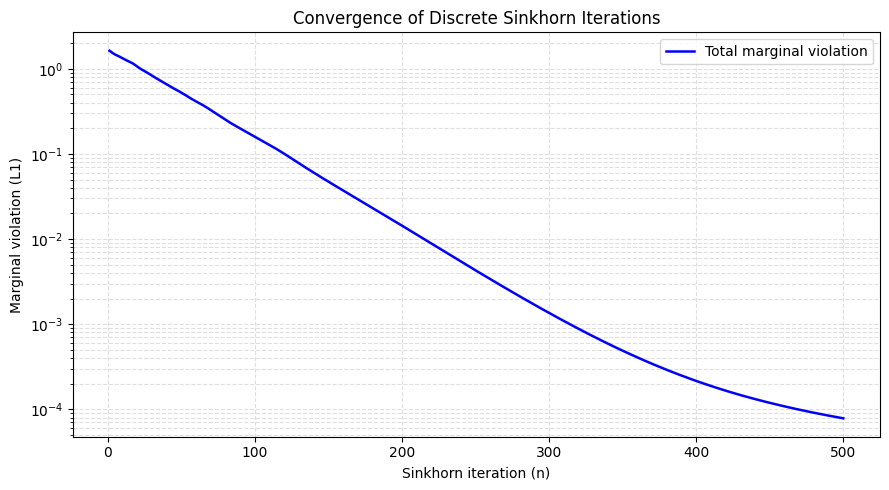

Initial marginal violation: 1.630488e+00
Final marginal violation: 7.833399e-05


In [ ]:
# Figure (base experiment, alpha = 0.05): kept for reference; the report now uses only the alpha comparison below.
import torch
import matplotlib.pyplot as plt

def sinkhorn_convergence(
    N=100,
    M=100,
    alpha=0.1,
    num_iterations=500,
    seed=42
):

  if alpha <= 0:
    raise ValueError("alpha must be strictly positive.")
  torch.manual_seed(seed)

  # ---------------------------------------------------------
  # 1. Define empirical probability distributions
  # ---------------------------------------------------------

  dtype = torch.float64

  pi_0 = torch.ones(N, dtype=dtype) / N
  pi_T = torch.ones(M, dtype=dtype) / M

  # Generate spatial points
  x = torch.randn(N, 2, dtype=dtype)
  y = torch.randn(M, 2, dtype=dtype) + torch.tensor(
      [2.0, 2.0], dtype=dtype
  )


  # ---------------------------------------------------------
  # 2. Compute the cost matrix
  # ---------------------------------------------------------

  # x = source of points, y = destination, p=2= type of norme
  C = torch.cdist(x,y, p=2) ** 2

  # Instead of computing K = exp(-C/ alpha)
  # work directly with log(K)

  log_K = -C / alpha




  # ---------------------------------------------------------
  # 3. Initialize log-domain scaling vectors
  # ---------------------------------------------------------

  log_u = torch.zeros(N, dtype=dtype)
  log_v = torch.zeros(M, dtype=dtype)

  log_pi_0 = torch.log(pi_0)
  log_pi_T = torch.log(pi_T)

  marginal_errors = []

  # --------------------------------------------------
  # 4. Sinkhorn alternating updates
  # --------------------------------------------------

  for n in range(num_iterations):

    # Update v
    log_v = log_pi_T - torch.logsumexp(
        log_K + log_u[:, None],
        dim=0
    )

    # Update u
    log_u = log_pi_0 - torch.logsumexp(
        log_K + log_v[None, :],
        dim=1
    )

    # --------------------------------------------------
    # 5. Compute marginal violations
    # --------------------------------------------------

    # log(P_ij) = log(u_i) + log(K_ij) + log(v_j)

    log_P = (
        log_u[:,None]
        + log_K
        + log_v[None, :]
    )

    # Compute marginal distributions in log domain
    current_pi_0_hat = torch.exp(
        torch.logsumexp(log_P, dim=1)
    )

    current_pi_T_hat = torch.exp(
        torch.logsumexp(log_P, dim=0)
    )

    # L1 marginal violations
    error_0 = torch.sum(
        torch.abs(current_pi_0_hat - pi_0)
    )

    error_T = torch.sum(
        torch.abs(current_pi_T_hat - pi_T)
    )

    total_error = error_0 + error_T

    marginal_errors.append(total_error.item())

  return marginal_errors


# --------------------------------------------------
# 6. Execute and visualize convergence
# --------------------------------------------------

errors = sinkhorn_convergence(
    N=200,
    M=200,
    alpha=0.05,
    num_iterations=500
)

plt.figure(figsize=(9, 5))

plt.semilogy(
    range(1, len(errors)+1),
    errors,
    color="blue",
    linewidth=1.8,
    label="Total marginal violation"
)

plt.xlabel("Sinkhorn iteration (n)")
plt.ylabel("Marginal violation (L1)")
plt.title("Convergence of Discrete Sinkhorn Iterations")

plt.grid(
    visible=True,
    which="both",
    linestyle="--",
    alpha=0.4
)

plt.legend()
plt.tight_layout()
plt.show()

print(f"Initial marginal violation: {errors[0]:.6e}")
print(f"Final marginal violation: {errors[-1]:.6e}")




## Experiment setup

- Source $\pi_0$: $N=200$ i.i.d. samples $x_i \sim \mathcal{N}(0, I_2)$, uniform weights $a_i = 1/N$.
- Target $\pi_T$: $M=200$ i.i.d. samples $y_j \sim \mathcal{N}((2,2), I_2)$, uniform weights $b_j = 1/M$.
- Cost: squared Euclidean distance $C_{ij} = \|x_i - y_j\|_2^2$.
- Seed 42, float64, log-domain (stabilized) Sinkhorn, $v$ updated before $u$.

Below: effect of $\alpha$ on convergence (Figure 1 in the report).

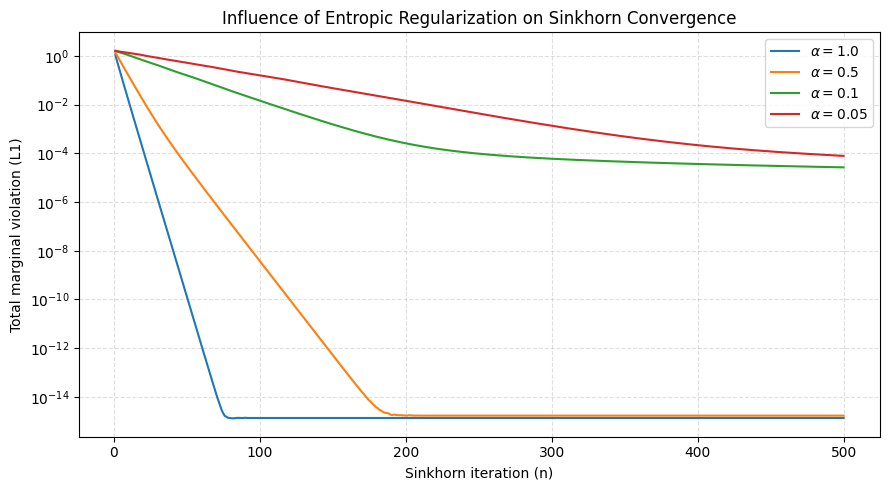

In [ ]:
alphas = [1.0, 0.5, 0.1, 0.05]

plt.figure(figsize=(9,5))

for alpha in alphas:

    errors = sinkhorn_convergence(
        N=200,
        M=200,
        alpha=alpha,
        num_iterations=500,
        seed=42
    )

    plt.semilogy(
        range(1, len(errors)+1),
        errors,
        label=rf"$\alpha = {alpha}$"
    )

plt.xlabel("Sinkhorn iteration (n)")
plt.ylabel("Total marginal violation (L1)")
plt.title("Influence of Entropic Regularization on Sinkhorn Convergence")

plt.legend()
plt.grid(visible=True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## Shared helpers for the additional experiments

In [ ]:
import torch

def sample_problem(N=200, M=200, seed=42):
    """Same sampling as in sinkhorn_convergence (same seed => same points)."""
    torch.manual_seed(seed)
    dtype = torch.float64
    x = torch.randn(N, 2, dtype=dtype)
    y = torch.randn(M, 2, dtype=dtype) + torch.tensor([2.0, 2.0], dtype=dtype)
    C = torch.cdist(x, y, p=2) ** 2
    return x, y, C

def sinkhorn_log(C, alpha, max_iterations=20000, tol=None):
    """Log-domain Sinkhorn with optional tolerance stopping. Returns (errors, P)."""
    N, M = C.shape
    dtype = C.dtype
    log_pi_0 = torch.log(torch.ones(N, dtype=dtype) / N)
    log_pi_T = torch.log(torch.ones(M, dtype=dtype) / M)
    log_K = -C / alpha
    log_u = torch.zeros(N, dtype=dtype)
    errors = []
    for n in range(max_iterations):
        log_v = log_pi_T - torch.logsumexp(log_K + log_u[:, None], dim=0)
        log_u = log_pi_0 - torch.logsumexp(log_K + log_v[None, :], dim=1)
        log_P = log_u[:, None] + log_K + log_v[None, :]
        err = (torch.exp(torch.logsumexp(log_P, 1)) - torch.exp(log_pi_0)).abs().sum() \
            + (torch.exp(torch.logsumexp(log_P, 0)) - torch.exp(log_pi_T)).abs().sum()
        errors.append(err.item())
        if tol is not None and err.item() < tol:
            break
    return errors, torch.exp(log_P)


## Convergence tolerance: iterations to reach $E^{(n)} < 10^{-6}$ (Table in the report)

In [ ]:
# Iterations needed to reach a total marginal violation below tol = 1e-6
x, y, C = sample_problem()
tol = 1e-6
print(f"{'alpha':>6} | {'iterations':>10} | {'E(500)':>9} | {'cost <C,P>':>10} | {'targets/source':>14} | {'K underflow':>11}")
for alpha in [1.0, 0.5, 0.1, 0.05]:
    errors, P = sinkhorn_log(C, alpha, tol=tol)
    n_iter = len(errors) if errors[-1] < tol else None
    E500 = sinkhorn_log(C, alpha, max_iterations=500)[0][-1]
    # spread: average number of targets receiving > 0.1% of a source's mass
    spread = ((P * C.shape[0]) > 1e-3).sum(dim=1).double().mean().item()
    underflow = (torch.exp(-C / alpha) == 0).double().mean().item()
    print(f"{alpha:>6} | {str(n_iter):>10} | {E500:>9.1e} | {(C * P).sum().item():>10.4f} | {spread:>14.1f} | {underflow:>10.1%}")

# Unregularized OT baseline (uniform weights, N = M => optimal plan is a permutation)
from scipy.optimize import linear_sum_assignment
r, c = linear_sum_assignment(C.numpy())
print("Unregularized OT cost:", C.numpy()[r, c].mean())


## What the entropic plans look like

In [ ]:
# Transport plans for a large and a small alpha (Figure 2 in the report)
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, alpha in zip(axs, [1.0, 0.05]):
    _, P = sinkhorn_log(C, alpha, tol=1e-6)
    W = (P / P.max()).numpy()
    for i, j in zip(*(W > 0.02).nonzero()):
        ax.plot([x[i, 0], y[j, 0]], [x[i, 1], y[j, 1]], color="0.35", lw=0.6, alpha=min(1.0, W[i, j]) * 0.6)
    ax.scatter(x[:, 0], x[:, 1], s=12, color="tab:blue", label=r"source samples $x_i \sim \pi_0$", zorder=3)
    ax.scatter(y[:, 0], y[:, 1], s=12, color="tab:red", label=r"target samples $y_j \sim \pi_T$", zorder=3)
    ax.set_title(rf"Entropic transport plan, $\alpha = {alpha}$")
    ax.grid(ls="--", alpha=0.4); ax.set_aspect("equal")
axs[0].legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()


## Running example (2 x 2 toy problem)

In [ ]:
# Running example of the report: two sources, two targets, C = [[0, 1], [1, 0]], uniform weights.
# Closed form: P_11 = P_22 = 1 / (2 (1 + exp(-1/alpha))), reached after ONE Sinkhorn sweep (symmetry).
C_toy = torch.tensor([[0.0, 1.0], [1.0, 0.0]], dtype=torch.float64)
for alpha in [1.0, 0.5, 0.1]:
    errors, P = sinkhorn_log(C_toy, alpha, max_iterations=3)
    closed = 1 / (2 * (1 + torch.exp(torch.tensor(-1 / alpha))))
    print(f"alpha={alpha}: P=\n{P.numpy().round(4)}\n  closed-form P_11={closed.item():.4f}, errors={errors}")
